# G1 RSS output — categories

Distribution of article categories (an article may belong to several).

Using data file: /home/user/g1/g1_articles.jsonl
Top categories:
categories
G1    6057
g1     144


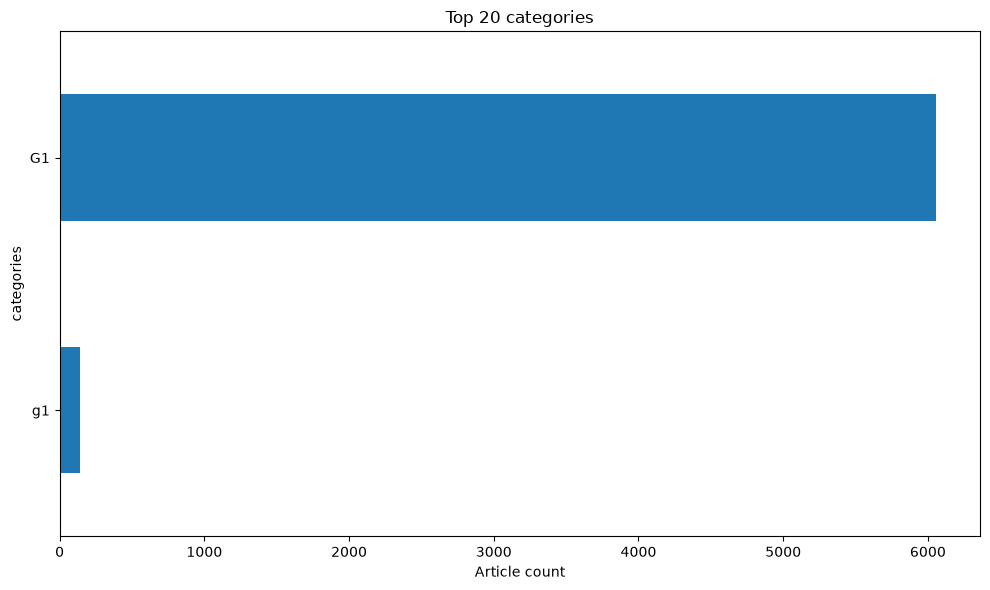

In [1]:

from pathlib import Path
import json

def find_data_file():
    candidates = [Path("g1_articles.jsonl"), Path("../g1_articles.jsonl"), Path("../../g1_articles.jsonl")]
    for c in candidates:
        if c.exists():
            return c
    for p in Path.cwd().rglob("g1_articles.jsonl"):
        return p
    raise FileNotFoundError("g1_articles.jsonl not found")

DATA_FILE = find_data_file()
print("Using data file:", DATA_FILE.resolve())

import pandas as pd
import matplotlib
matplotlib.use("Agg")
import matplotlib.pyplot as plt
rows = [json.loads(line) for line in DATA_FILE.read_text(encoding="utf-8").splitlines() if line.strip()]
df = pd.DataFrame(rows)
cats = df["categories"].explode().dropna()
cats = cats[cats.astype(str).str.strip() != ""]
vc = cats.value_counts().head(20)
print("Top categories:")
print(vc.to_string())
fig, ax = plt.subplots(figsize=(10, 6))
vc[::-1].plot(kind="barh", ax=ax, color="#1f77b4")
ax.set_title("Top 20 categories")
ax.set_xlabel("Article count")
plt.tight_layout()


Using data file: /home/user/g1/g1_articles.jsonl


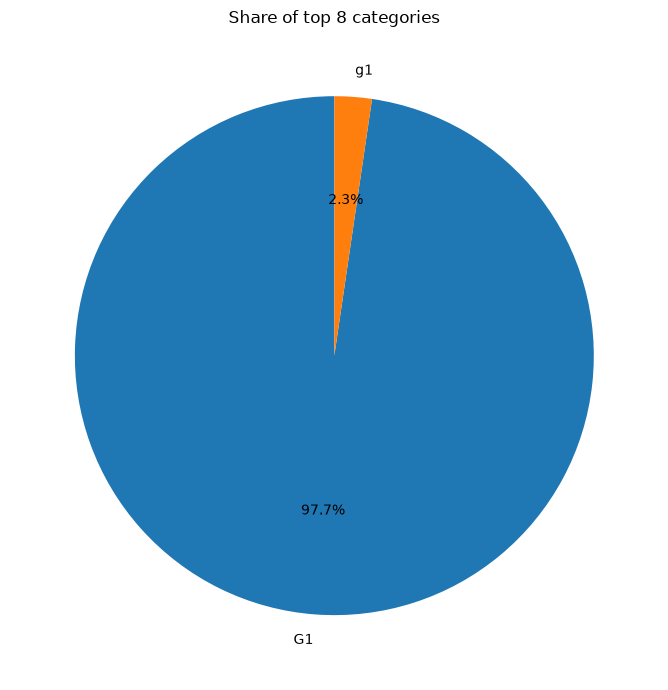

In [2]:

from pathlib import Path
import json

def find_data_file():
    candidates = [Path("g1_articles.jsonl"), Path("../g1_articles.jsonl"), Path("../../g1_articles.jsonl")]
    for c in candidates:
        if c.exists():
            return c
    for p in Path.cwd().rglob("g1_articles.jsonl"):
        return p
    raise FileNotFoundError("g1_articles.jsonl not found")

DATA_FILE = find_data_file()
print("Using data file:", DATA_FILE.resolve())

import pandas as pd
import matplotlib
matplotlib.use("Agg")
import matplotlib.pyplot as plt
rows = [json.loads(line) for line in DATA_FILE.read_text(encoding="utf-8").splitlines() if line.strip()]
df = pd.DataFrame(rows)
cats = df["categories"].explode().dropna()
cats = cats[cats.astype(str).str.strip() != ""]
vc = cats.value_counts().head(8)
fig, ax = plt.subplots(figsize=(7, 7))
vc.plot(kind="pie", ax=ax, autopct="%1.1f%%", startangle=90)
ax.set_ylabel("")
ax.set_title("Share of top 8 categories")
plt.tight_layout()
